# Plan 2 · Part B: does the 7B grade buildings better than our grader, given a zoomed-in crop?

> **A test against ground truth.** Built on 29 Oct 2026 from Abrar's Part B instructions, after Abrar checked Part A. The design, the choices and the decision rule below were fixed before the run.

**Author:** Tamanna (Member B) · **Group:** CSE499B Group 5 · **Folder:** `Essential_task_delegation/Tamanna_task_2/Plan_2/`

## The question
Does the 7B grade a building better than our find-then-grade grader (R16c step 5b) when it sees a zoomed-in crop of that building?

## Design (Abrar's six points)
1. **Buildings from the validation ground truth, not from R9:** a true building is an 8-connected piece of one true class of at least 20 px, the same rule as R16c step 5b's grader table. E5's 40 leaked validation pairs are left out, so 605 images remain.
2. **A balanced sample:** the same number of true buildings from each class, drawn with seed 42.
3. **The target is marked:** a red box around the building in each crop, and the prompt says "the building in the red box".
4. **No answer in the prompt:** the prompts never contain the true class or a segmenter's class. They are the same text for every building.
5. **Two models:** the new fine-tuned 7B, `AbrarAlam/disasterm3-qwen2.5vl7b-l0s2-mergedFP` (kept after L0 step 2's top-up training at full image size), and the base 7B, `Qwen/Qwen2.5-VL-7B-Instruct`, on the same crops.
6. **Scoring:** a 3×3 confusion matrix against the true class and per-class recall. The sample is balanced, so recall is compared, not F1. The grader is compared two ways:
   - **On the same buildings (primary),** as the ledger's Part B note says (§9, 28 Oct). Cell 6 loads R16c step 5b's saved grader (`grader_seed44.pth`, with its biases), regrades all 25,594 true validation buildings to check that it reproduces `grader_true_buildings.csv`, and then grades the sampled buildings.
   - **Against its recorded recall (secondary):** Intact 0.94, Damaged 0.67, Destroyed 0.70 on the true validation buildings it grades, computed in Cell 2 from that file's counts.

## Choices made here (to confirm with Abrar before the commit run)
- **100 buildings per class.** Abrar's example was 20. With 20, a recall of 14/20 has a 95% Wilson interval of 0.48–0.85, too wide to separate the 7B from the grader; with 100, 70/100 gives 0.60–0.78.
- **At most 3 buildings of a class from one image,** so a few large images can't fill the sample. If 3 isn't enough to reach 100, the cap rises to 5, then 10, then none; Cell 4 prints the cap used.
- **The crop:** a 256 px window of the after-image at native resolution, centred on the building, enlarged 2× to 512 px for the model. A building too long for that window gets a larger window, resized to 512 px.
- **The red box:** 2 px wide, 4 px outside the building's bounding box.
- **The class prompt** gives the xBD joint damage scale (Gupta et al. 2019, Figure 4), with minor and major damage merged into "Damaged" as DisasterM3 does. A second prompt asks for the EMS-98 grade, used only to check whether the model's two answers agree.
- **Both 7Bs in fp16 on two T4s, with greedy decoding,** as in L0. Part A's demo used 4-bit; H2b found that 4-bit costs our 7B accuracy.
- **Answers that name no class, or more than one, are "unparsed".** In the paired comparison a building counts as right only if the answer names its true class, so an unparsed answer, like the grader's "None", counts as wrong. The recall table also gives recall on parsed answers only, matching how the grader's recorded figures leave out its "None" grades.

## Known before the run
- **The grader sees more:** the before-image as well as the after-image (a 128 px crop of each, with the building's mask). The 7Bs see only the after-image crop, as Abrar's instructions specify; a before-and-after version for the 7B is H3's V3.
- **The fine-tuned 7B has seen these images:** it was trained on DisasterM3 Instruct's text tasks (counting, captions and others), and the ledger notes that the 7B was trained on Instruct images (§4, E5). These 605 images are Instruct images, though no per-building labels were in that training. The base 7B and the grader never trained on them.
- **The grader's recorded figures** cover all 645 validation images, the 40 leaked pairs included, and every true building rather than a balanced sample. The paired comparison avoids both differences.

## Decision rule (fixed before the run)
- **The main question, per 7B:** on the same buildings, an exact McNemar test of the 7B against the grader over all sampled buildings: "7B higher" if p < 0.05 and the 7B is right on more of the buildings where the two differ, "7B lower" if p < 0.05 the other way, otherwise "not distinguishable at this sample size". The same test is reported per class.
- **Secondary:** per class and for the mean of the three recalls, the grader's recorded recall against the 7B's 95% interval (Wilson per class, a stratified bootstrap for the mean), with the same three verdicts.
- **The grader's check:** its regrade of the true validation buildings must match `grader_true_buildings.csv` to within 0.2% of the buildings, or the run stops.
- No number was predicted.

## How to run on Kaggle
1. **Settings:** GPU T4 ×2, internet on.
2. **Inputs:** the `abrarmohammedtanzim/disasterm3-mirror` dataset, and R16c step 5b's output (the notebook `r16c-step5b-third-grader-seed`, shared by Abrar), which holds `grader_seed44.pth`. No secret is needed: both 7Bs are public.
3. **Check:** set `SMOKE_TEST = True` in Cell 2 (3 buildings per class; the grader's check still runs in full), then Restart & Run All.
4. **Commit:** set `SMOKE_TEST = False`, then Save Version → Save & Run All (Commit).
5. **Outputs** in `/kaggle/working/part_b/`: `part_b_sample.csv`, `part_b_answers.csv`, `part_b_grader_check.csv`, `part_b_confusion.csv`, `part_b_recall.csv`, `part_b_paired.csv`, `part_b_config.json`, `part_b_examples.png` and `part_b_recall_chart.png`.


## 1. Environment

In [1]:
# ── Cell 1: Environment (Kaggle's own torch; transformers only if too old for Qwen2.5-VL) ──
import importlib.metadata as _md
import os
import subprocess
import sys

# The outputs must come from one Restart & Run All. A kernel that already ran cells keeps their state, so an
# interactive run stops here unless this is the kernel's first cell. Save & Run All (Commit) always starts fresh.
if os.environ.get("KAGGLE_KERNEL_RUN_TYPE") != "Batch" and get_ipython().execution_count != 1:
    raise SystemExit("This kernel has already run cells. Run > Restart & clear cell outputs, then Run All, "
                     "so that every output comes from one fresh run.")

def _version(pkg):
    try:
        return _md.version(pkg)
    except _md.PackageNotFoundError:
        return "0"

def _older(have, want):
    nums = lambda v: tuple(int(x) for x in v.split(".")[:2] if x.isdigit())
    return nums(have) < nums(want)

installs = []
if _older(_version("transformers"), "4.49"):
    installs.append("transformers>=4.49")      # Qwen2.5-VL
if _version("accelerate") == "0":
    installs.append("accelerate")              # device_map over both T4s
if installs:
    print(f"Installing {installs}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *installs], check=True)   # a pip failure stops here

import torch
import transformers
print(f"torch {torch.__version__}, transformers {transformers.__version__}, python {sys.version.split()[0]}")
print(f"GPUs: {[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}")
assert torch.cuda.device_count() >= 2, "Pick GPU T4 x2: each 7B in fp16 needs both T4s"

torch 2.11.0+cu128, transformers 5.16.1, python 3.13.15
GPUs: ['Tesla T4', 'Tesla T4']


## 2. Configuration

In [2]:
# ── Cell 2: Configuration ──
import gc
import glob
import json
import re
import time
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

MODELS = {   # run name: Hugging Face repo (both public)
    "finetuned": "AbrarAlam/disasterm3-qwen2.5vl7b-l0s2-mergedFP",   # the 7B kept after L0 step 2's top-up training
    "base": "Qwen/Qwen2.5-VL-7B-Instruct",                            # the base model, no fine-tuning
}
SMOKE_TEST = False         # True = 3 buildings per class, to check the notebook end to end
N_PER_CLASS = 100           # balanced sample: this many true buildings of each class
CAPS = (3, 5, 10, None)     # most buildings of one class from one image; the smallest cap that reaches N is used
SEED = 42
MIN_AREA = 20               # a true building: an 8-connected piece of one class of at least this many px (R16c's rule)
WINDOW = 256                # crop window of the after-image, native resolution
ZOOM = 2                    # the window is enlarged this many times for the model (256 -> 512 px)
BOX_PAD, BOX_THICK = 4, 2   # the red box: px outside the building's box (native), line width (enlarged)
CONTEXT = 16                # px kept around a building too long for the window
BATCH = 8                   # crops per generate() call; halved on out-of-memory
BOOTSTRAP = 2000            # resamples for the interval of the mean recall
CLASSES = ["Intact", "Damaged", "Destroyed"]
LABEL = "Part B: test against ground truth"
OUT_DIR = Path("/kaggle/working/part_b")
OUT_DIR.mkdir(parents=True, exist_ok=True)
if SMOKE_TEST:
    N_PER_CLASS = 3

# E5's 40 leaked validation pairs (Champion_Task/E5-results/E5/leaked_pairs_40.csv), left out of the sample
LEAK40 = {
    "socal_fire_00000081_post_disaster.png", "socal_fire_00000188_post_disaster.png",
    "socal_fire_00000218_post_disaster.png", "socal_fire_00000220_post_disaster.png",
    "socal_fire_00000222_post_disaster.png", "socal_fire_00000235_post_disaster.png",
    "socal_fire_00000301_post_disaster.png", "socal_fire_00000341_post_disaster.png",
    "socal_fire_00000348_post_disaster.png", "socal_fire_00000396_post_disaster.png",
    "socal_fire_00000436_post_disaster.png", "socal_fire_00000455_post_disaster.png",
    "socal_fire_00000497_post_disaster.png", "socal_fire_00000504_post_disaster.png",
    "socal_fire_00000614_post_disaster.png", "socal_fire_00001188_post_disaster.png",
    "woolsey_fire_00000009_post_disaster.png", "woolsey_fire_00000030_post_disaster.png",
    "woolsey_fire_00000032_post_disaster.png", "woolsey_fire_00000137_post_disaster.png",
    "woolsey_fire_00000272_post_disaster.png", "woolsey_fire_00000399_post_disaster.png",
    "woolsey_fire_00000435_post_disaster.png", "woolsey_fire_00000474_post_disaster.png",
    "woolsey_fire_00000498_post_disaster.png", "woolsey_fire_00000514_post_disaster.png",
    "woolsey_fire_00000529_post_disaster.png", "woolsey_fire_00000573_post_disaster.png",
    "woolsey_fire_00000576_post_disaster.png", "woolsey_fire_00000589_post_disaster.png",
    "woolsey_fire_00000623_post_disaster.png", "woolsey_fire_00000632_post_disaster.png",
    "woolsey_fire_00000634_post_disaster.png", "woolsey_fire_00000653_post_disaster.png",
    "woolsey_fire_00000679_post_disaster.png", "woolsey_fire_00000703_post_disaster.png",
    "woolsey_fire_00000722_post_disaster.png", "woolsey_fire_00000758_post_disaster.png",
    "woolsey_fire_00000783_post_disaster.png", "woolsey_fire_00000810_post_disaster.png",
}
assert len(LEAK40) == 40

# R16c step 5b's grader (seed 44): its file, labels, crop and biases (R16c-results/step5b/calibration.json)
GRADER_FILE = "grader_seed44.pth"
GRADER_LABELS = ["Intact", "Damaged", "Destroyed", "None"]
GRADER_CROP, GRADER_MARGIN = 128, 32
GRADER_BIAS = {"Intact": 0.0, "Damaged": -2.0, "Destroyed": -4.0, "None": -3.5}
GRADER_TOLERANCE = 0.002    # its regrade of the true validation buildings must match the file to within 0.2%
# Its recorded grades of the true validation buildings (R16c-results/step5b/grader_true_buildings.csv):
# rows the true class, columns graded Intact, Damaged, Destroyed, None
GRADER_COUNTS = {"Intact": [17878, 806, 339, 601], "Damaged": [1230, 2841, 178, 121], "Destroyed": [208, 229, 1031, 132]}
GRADER_RECALL = {c: row[i] / (sum(row) - row[3]) for i, (c, row) in enumerate(GRADER_COUNTS.items())}   # on graded
_FILE = {"Intact": (19624, 0.911), "Damaged": (4370, 0.6501), "Destroyed": (1600, 0.6444)}   # buildings, recall column
assert all(sum(GRADER_COUNTS[c]) == _FILE[c][0] and round(GRADER_COUNTS[c][i] / _FILE[c][0], 4) == _FILE[c][1]
           for i, c in enumerate(CLASSES)), "grader counts mistyped"

_fixed = Path("/kaggle/input/datasets/abrarmohammedtanzim/disasterm3-mirror/DisasterM3_Instruct/train_release.json")
_found = [_fixed] if _fixed.exists() else sorted(
    Path(p) for p in glob.glob("/kaggle/input/**/DisasterM3_Instruct/train_release.json", recursive=True))
assert _found, "Attach the abrarmohammedtanzim/disasterm3-mirror dataset"
MANIFEST_PATH = _found[0]
DATA_ROOT = MANIFEST_PATH.parent

print(f"{LABEL}{'  [SMOKE TEST]' if SMOKE_TEST else ''}: {N_PER_CLASS} true buildings per class, models {list(MODELS)}")
print("Grader's recorded recall on the buildings it grades: "
      + ", ".join(f"{c} {GRADER_RECALL[c]:.4f}" for c in CLASSES)
      + f"; mean {np.mean(list(GRADER_RECALL.values())):.4f}")
print(f"DisasterM3 list: {MANIFEST_PATH}")

Part B: test against ground truth: 100 true buildings per class, models ['finetuned', 'base']
Grader's recorded recall on the buildings it grades: Intact 0.9398, Damaged 0.6686, Destroyed 0.7023; mean 0.7703
DisasterM3 list: /kaggle/input/datasets/abrarmohammedtanzim/disasterm3-mirror/DisasterM3_Instruct/train_release.json


## 3. The validation split
The same 645 images as every D4 run, without E5's 40 leaked pairs.

In [3]:
# ── Cell 3: The team's validation split, without E5's 40 leaked pairs ──
from sklearn.model_selection import train_test_split

t_cell = time.time()
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    raw_data = json.load(f)
print(f"Loaded {len(raw_data):,} entries")

def name_of(path):
    return Path(str(path).replace("\\", "/")).name

# The D4 notebooks' (image, masks) pairs, in their order, so the split gives the same 645 validation images
# (as in Part A: one directory listing per folder, and the count check proves the pairs are the D4 ones).
# Only optical entries are used, by DisasterM3's own type field, as in every D4 run.
bda_entries = [e for e in raw_data
               if e.get("task") == "Referring Expression Segmentation"
               and e.get("cls_description") == "Building Damage Assessment"]

_listing = {}
def exists(path):
    """Path(path).exists() for a file, through one listing of its folder."""
    folder, name = os.path.split(str(path))
    if folder not in _listing:
        _listing[folder] = set(os.listdir(folder)) if os.path.isdir(folder) else set()
    return name in _listing[folder]

def resolve_path(rel_path):
    if not rel_path:
        return None
    rel_path = rel_path.replace("\\", "/")
    filename = Path(rel_path).name
    candidates = [
        DATA_ROOT / rel_path,
        DATA_ROOT / "train_images" / rel_path,
        DATA_ROOT / "train_images" / "train_images" / filename,
        DATA_ROOT / "masks" / rel_path,
        DATA_ROOT / "masks" / "masks" / filename,
    ]
    for c in candidates:
        if exists(c):
            return str(c)
    return None

by_image = defaultdict(dict)   # post_image_path -> {mask folder: mask path}
pre_rel = {}                   # post_image_path -> the before-image's path in the list (for the grader)
for e in bda_entries:
    post_img = e.get("post_image_path", "")
    if e.get("image_type") != "Optical":
        continue
    mask_rel = e.get("ground_truth", "")
    folder = Path(mask_rel.replace("\\", "/")).parent.name
    resolved = resolve_path(mask_rel)
    if resolved:
        by_image[post_img][folder] = resolved
        pre_rel[post_img] = e.get("pre_image_path")

FOLDER_TO_CLASS = {
    "train_building_intact_mask": 1,
    "train_building_damaged_mask": 2,
    "train_building_destroyed_mask": 3,
}

pairs = []
for post_img, mask_dict in by_image.items():
    img_path = resolve_path(post_img)
    if img_path and any(folder in FOLDER_TO_CLASS for folder in mask_dict):
        pairs.append({"image_path": img_path, "mask_paths": dict(mask_dict), "pre_rel": pre_rel.get(post_img)})

assert len(pairs) == 6443, f"{len(pairs)} pairs, not the D4 notebooks' 6,443: the split would differ"
train_pairs, val_pairs = train_test_split(pairs, test_size=0.1, random_state=42)
assert len(val_pairs) == 645, f"{len(val_pairs)} validation images, not the team's 645: the split differs"

clean_pairs = sorted((p for p in val_pairs if name_of(p["image_path"]) not in LEAK40),
                     key=lambda p: name_of(p["image_path"]))
assert len(clean_pairs) == 605, f"{len(clean_pairs)} clean validation images, not 605: check LEAK40 against the split"
path_of = {name_of(p["image_path"]): p["image_path"] for p in clean_pairs}
pair_of = {name_of(p["image_path"]): p for p in val_pairs}
print(f"Pairs: {len(pairs):,}; validation images: {len(val_pairs)}; without the 40 leaked pairs: {len(clean_pairs)} "
      f"({time.time() - t_cell:.0f} s)")

Loaded 92,968 entries
Pairs: 6,443; validation images: 645; without the 40 leaked pairs: 605 (6 s)


## 4. True buildings and the balanced sample
The sample is drawn and saved before any model runs.

In [4]:
# ── Cell 4: The true buildings of the 605 images, and the balanced sample ──
XBD_NAME = re.compile(r"^(.+?)_(\d{8})_post_disaster")
OTHER_NAME = re.compile(r"^(.+?)_post")

def event_and_source(image_name):
    """As in E1: 'hurricane_florence_00000261_post_disaster.png' -> ('hurricane_florence', 'xBD')."""
    m = XBD_NAME.match(image_name)
    if m:
        return m.group(1), "xBD"
    m = OTHER_NAME.match(image_name)
    return re.sub(r"\d+$", "", m.group(1) if m else Path(image_name).stem), "other"

def true_mask(pair, shape):
    """The 4-class mask exactly as the D4 notebooks build it (later classes overwrite earlier), at the image's size."""
    gt = None
    for folder, cls in FOLDER_TO_CLASS.items():
        path = pair["mask_paths"].get(folder)
        m = cv2.imread(path, cv2.IMREAD_GRAYSCALE) if path else None
        if m is None:
            continue
        if gt is None:
            gt = np.zeros_like(m, dtype=np.uint8)
        gt[m > 0] = cls
    if gt is not None and gt.shape != shape:
        gt = cv2.resize(gt, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
    return gt

def pieces(gt):
    """True buildings: the 8-connected pieces of each true class of at least MIN_AREA px (R16c step 5b's rule)."""
    out = []
    for cls in (1, 2, 3):
        n, _, stats, _ = cv2.connectedComponentsWithStats((gt == cls).astype(np.uint8), connectivity=8)
        for i in range(1, n):
            x, y, w, h, area = (int(v) for v in stats[i, :5])
            if area >= MIN_AREA:
                out.append({"true_class": CLASSES[cls - 1], "piece_id": i, "x": x, "y": y, "w": w, "h": h, "area_px": area})
    return out

# Self-check: one piece per class, the 4-pixel piece below MIN_AREA left out, diagonal pixels joined (8-connected)
_gt = np.zeros((200, 300), np.uint8)
_gt[0:10, 0:20], _gt[100:150, 200:260], _gt[190:192, 0:2] = 3, 1, 2
_gt[50:55, 50:55], _gt[55:60, 55:60] = 2, 2
assert sorted((p["true_class"], p["area_px"]) for p in pieces(_gt)) == [("Damaged", 50), ("Destroyed", 200), ("Intact", 3000)]

rows = []
t_cell = time.time()
for pair in clean_pairs:
    name = name_of(pair["image_path"])
    with Image.open(pair["image_path"]) as im:              # reads the header only
        width, height = im.size
    gt = true_mask(pair, (height, width))
    if gt is None:
        continue
    event, source = event_and_source(name)
    for p in pieces(gt):
        rows.append({"image": name, "event": event, "source": source, "image_w": width, "image_h": height, **p})
buildings = pd.DataFrame(rows)
buildings["longest_px"] = buildings[["w", "h"]].max(axis=1)
print(f"True buildings in the {len(clean_pairs)} images ({(time.time() - t_cell) / 60:.1f} min):")
print(buildings.groupby("true_class")["longest_px"].agg(buildings="size", median_longest_side_px="median")
      .reindex(CLASSES).to_string())
print(f"Median longest side, all classes: {buildings['longest_px'].median():.0f} px")

# The balanced sample: per class, a seeded random order, keeping at most `cap` buildings of that class per image
rng = np.random.default_rng(SEED)
picked, caps_used = [], {}
for cls in CLASSES:
    cand = buildings[buildings["true_class"] == cls].reset_index(drop=True)
    order = rng.permutation(len(cand))
    for cap in CAPS:
        per_image, taken = Counter(), []
        for i in order:
            name = cand.at[i, "image"]
            if cap is None or per_image[name] < cap:
                taken.append(i)
                per_image[name] += 1
            if len(taken) == N_PER_CLASS:
                break
        if len(taken) == N_PER_CLASS:
            break
    assert len(taken) == N_PER_CLASS, f"only {len(taken)} {cls} buildings available"
    caps_used[cls] = cap
    picked.append(cand.loc[taken])
sample = pd.concat(picked).sample(frac=1, random_state=SEED).reset_index(drop=True)   # classes interleaved
sample.insert(0, "item", range(len(sample)))
sample.to_csv(OUT_DIR / "part_b_sample.csv", index=False)
print(f"\nSample: {len(sample)} buildings from {sample['image'].nunique()} images; "
      f"cap per image and class: {caps_used}")
print(sample.groupby(["true_class", "source"]).size().unstack(fill_value=0).reindex(CLASSES).to_string())
print(f"Events: {sample['event'].nunique()}; saved {OUT_DIR / 'part_b_sample.csv'} before any model runs")

True buildings in the 605 images (2.1 min):
            buildings  median_longest_side_px
true_class                                   
Intact          19164                    46.0
Damaged          4348                    44.0
Destroyed        1374                    33.0
Median longest side, all classes: 45 px

Sample: 300 buildings from 180 images; cap per image and class: {'Intact': 3, 'Damaged': 3, 'Destroyed': 3}
source      other  xBD
true_class            
Intact         20   80
Damaged         6   94
Destroyed      18   82
Events: 22; saved /kaggle/working/part_b/part_b_sample.csv before any model runs


## 5. The crops
Each crop marks its building with a red box.

300 crops of 512 px; windows larger than 256 px: 2


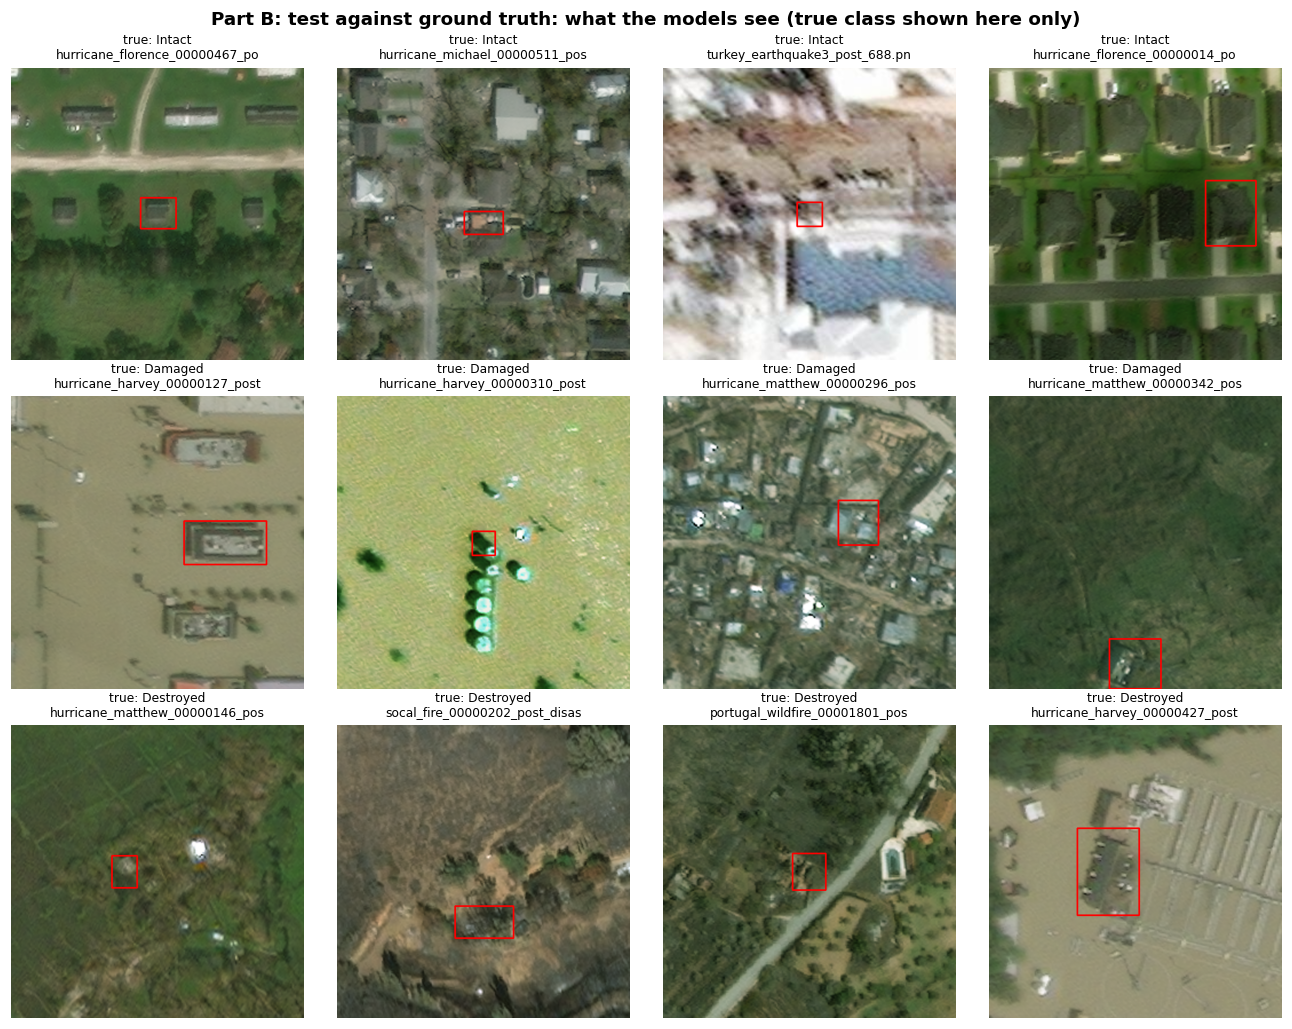

In [5]:
# ── Cell 5: One marked crop per building ──
OUT_PX = WINDOW * ZOOM

def window_for(x, y, w, h, H, W):
    """A square window of the after-image centred on the building: WINDOW px, or larger for a long building,
    kept inside the image. Returns (top, left, side)."""
    side = min(max(WINDOW, max(w, h) + 2 * (BOX_PAD + CONTEXT)), H, W)
    cx, cy = x + w / 2, y + h / 2
    left = int(round(min(max(cx - side / 2, 0), W - side)))
    top = int(round(min(max(cy - side / 2, 0), H - side)))
    return top, left, side

def marked_crop(post, x, y, w, h):
    """The window enlarged to OUT_PX, with a red box BOX_PAD px outside the building's bounding box."""
    H, W = post.shape[:2]
    top, left, side = window_for(x, y, w, h, H, W)
    scale = OUT_PX / side
    crop = cv2.resize(post[top:top + side, left:left + side], (OUT_PX, OUT_PX),
                      interpolation=cv2.INTER_CUBIC if scale > 1 else cv2.INTER_AREA)
    clamp = lambda v: int(min(max(round(v), 0), OUT_PX - 1))
    p0 = (clamp((x - BOX_PAD - left) * scale), clamp((y - BOX_PAD - top) * scale))
    p1 = (clamp((x + w + BOX_PAD - left) * scale), clamp((y + h + BOX_PAD - top) * scale))
    cv2.rectangle(crop, p0, p1, (255, 0, 0), BOX_THICK)      # RGB: red
    return np.ascontiguousarray(crop), side

# Self-checks: a building in a corner, a building longer than the window, the box drawn in red around it
_img = np.zeros((1024, 1024, 3), np.uint8)
_c, _side = marked_crop(_img, 0, 0, 30, 20)
assert _c.shape == (OUT_PX, OUT_PX, 3) and _side == WINDOW and _c[0, 0].tolist() == [255, 0, 0]
_c, _side = marked_crop(_img, 400, 400, 300, 120)
assert _side == 300 + 2 * (BOX_PAD + CONTEXT) and (_c[..., 0] == 255).sum() > 0 and _c[OUT_PX // 2, OUT_PX // 2].sum() == 0
_c, _side = marked_crop(np.zeros((200, 300, 3), np.uint8), 10, 10, 20, 20)    # image smaller than the window
assert _c.shape == (OUT_PX, OUT_PX, 3) and _side == 200

crops, windows = [None] * len(sample), [0] * len(sample)
for name, idx in sample.groupby("image").groups.items():   # each after-image read once
    post = cv2.cvtColor(cv2.imread(path_of[name]), cv2.COLOR_BGR2RGB)
    for i in idx:
        crops[i], windows[i] = marked_crop(post, *(int(v) for v in sample.loc[i, ["x", "y", "w", "h"]]))
sample["window_px"] = windows
sample.to_csv(OUT_DIR / "part_b_sample.csv", index=False)
print(f"{len(crops)} crops of {OUT_PX} px; windows larger than {WINDOW} px: {(sample['window_px'] > WINDOW).sum()}")

# Four examples per class, for people only (the models never see these titles)
fig, axes = plt.subplots(3, 4, figsize=(12, 9.5), dpi=110)
for ax in axes.ravel():
    ax.axis("off")
for row, cls in zip(axes, CLASSES):
    for ax, i in zip(row, sample.index[sample["true_class"] == cls][:4]):
        ax.imshow(crops[i])
        ax.set_title(f"true: {cls}\n{sample.at[i, 'image'][:30]}", fontsize=8)
        ax.axis("off")
fig.suptitle(f"{LABEL}: what the models see (true class shown here only)", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "part_b_examples.png", bbox_inches="tight")
plt.show()

## 6. R16c step 5b's grader on the same buildings
First a check: it must reproduce its recorded grades of every true validation building. Then it grades the sample.

In [6]:
# ── Cell 6: R16c step 5b's grader, checked against its recorded grades, then on the same buildings ──
# Its network, crops and normalisation are copied from r16c-step5b-third-grader-seed.ipynb (Cells 5 and 7).
import torch.nn as nn
import torchvision
from scipy import ndimage

DEVICE = torch.device("cuda")
_hits = sorted(glob.glob(f"/kaggle/input/**/{GRADER_FILE}", recursive=True))
assert _hits, (f"No {GRADER_FILE} under /kaggle/input. Add R16c step 5b's output as an input "
               "(+ Add Input > Notebooks > r16c-step5b-third-grader-seed, shared by Abrar).")
GRADER_PATH = _hits[0]

class SiameseGrader(nn.Module):
    """A shared ResNet-18 reads the before and the after crop (RGB + building mask each);
    [f_before, f_after, f_after - f_before] -> one score per label. As in step 5b, without the ImageNet download:
    every weight comes from the saved file."""

    def __init__(self):
        super().__init__()
        net = torchvision.models.resnet18(weights=None)
        net.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
        net.fc = nn.Identity()
        self.encoder = net
        self.head = nn.Sequential(nn.Linear(3 * 512, 256), nn.ReLU(inplace=True), nn.Dropout(0.2),
                                  nn.Linear(256, len(GRADER_LABELS)))

    def forward(self, before, after):
        fb, fa = self.encoder(before), self.encoder(after)
        return self.head(torch.cat([fb, fa, fa - fb], 1))

grader = SiameseGrader()
grader.load_state_dict(torch.load(GRADER_PATH, map_location="cpu"))   # strict: every weight must match
grader.to(DEVICE).eval()
BIAS = np.array([GRADER_BIAS[l] for l in GRADER_LABELS])
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1) * 255

def to_inputs(x):
    """uint8 (B, 7, S, S) -> normalised before and after tensors (B, 4, S, S); the mask becomes -1 / +1."""
    x = x.to(DEVICE, non_blocking=True).float()
    mask = x[:, 6:7] / 127.5 - 1
    return torch.cat([(x[:, 0:3] - MEAN) / STD, mask], 1), torch.cat([(x[:, 3:6] - MEAN) / STD, mask], 1)

@torch.no_grad()
def log_probs(crops):
    """uint8 crops (N, 7, S, S) -> log-probabilities (N, labels)."""
    out = []
    for i in range(0, len(crops), 512):
        before, after = to_inputs(torch.from_numpy(np.ascontiguousarray(crops[i:i + 512])))
        with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
            out.append(torch.log_softmax(grader(before, after).float(), 1).cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, len(GRADER_LABELS)), np.float32)

def square_box(sl, h, w):
    """Square window around a building's (row, column) slices, GRADER_MARGIN px wider on each side, inside the image."""
    y0, y1, x0, x1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
    side = min(max(y1 - y0, x1 - x0) + 2 * GRADER_MARGIN, h, w)
    cy, cx = (y0 + y1) / 2, (x0 + x1) / 2
    top = int(round(min(max(cy - side / 2, 0), h - side)))
    left = int(round(min(max(cx - side / 2, 0), w - side)))
    return top, left, side

def grader_crops(pre, post, labels, ids):
    """labels: int map of building ids. uint8 (len(ids), 7, CROP, CROP): before RGB, after RGB, that building's mask."""
    h, w = labels.shape
    slices = ndimage.find_objects(labels)
    out = np.empty((len(ids), 7, GRADER_CROP, GRADER_CROP), np.uint8)
    for n, lid in enumerate(ids):
        top, left, side = square_box(slices[lid - 1], h, w)
        win = (slice(top, top + side), slice(left, left + side))
        out[n, 0:3] = cv2.resize(pre[win], (GRADER_CROP, GRADER_CROP), interpolation=cv2.INTER_LINEAR).transpose(2, 0, 1)
        out[n, 3:6] = cv2.resize(post[win], (GRADER_CROP, GRADER_CROP), interpolation=cv2.INTER_LINEAR).transpose(2, 0, 1)
        out[n, 6] = cv2.resize((labels[win] == lid).astype(np.uint8) * 255, (GRADER_CROP, GRADER_CROP),
                               interpolation=cv2.INTER_NEAREST)
    return out

def read_pair(pair):
    """After-image and before-image (RGB, same size) and the true mask, as step 5b reads them."""
    post = cv2.cvtColor(cv2.imread(pair["image_path"]), cv2.COLOR_BGR2RGB)
    h, w = post.shape[:2]
    pre_path = resolve_path(pair["pre_rel"])
    assert pre_path, f"no before-image for {name_of(pair['image_path'])}"
    pre = cv2.cvtColor(cv2.imread(pre_path), cv2.COLOR_BGR2RGB)
    if pre.shape != post.shape:
        pre = cv2.resize(pre, (w, h), interpolation=cv2.INTER_LINEAR)
    return post, pre, true_mask(pair, (h, w))

def class_pieces(gt, cls):
    """The id map and the stats of the 8-connected pieces of one true class (cls 1-3)."""
    _, labels, stats, _ = cv2.connectedComponentsWithStats((gt == cls).astype(np.uint8), connectivity=8)
    return labels, stats

# 1) The check: regrade every true building of the 645 validation images, as step 5b did
t0 = time.time()
regrade = np.zeros((3, len(GRADER_LABELS)), np.int64)
for pair in val_pairs:
    post, pre, gt = read_pair(pair)
    if gt is None:
        continue
    for cls in (1, 2, 3):
        labels, stats = class_pieces(gt, cls)
        ids = [i for i in range(1, len(stats)) if stats[i, cv2.CC_STAT_AREA] >= MIN_AREA]
        if ids:
            graded = (log_probs(grader_crops(pre, post, labels, ids)) + BIAS).argmax(1)
            np.add.at(regrade, (np.full(len(ids), cls - 1), graded), 1)
expected = np.array([GRADER_COUNTS[c] for c in CLASSES])
check = pd.DataFrame(regrade, index=CLASSES, columns=[f"graded {l}" for l in GRADER_LABELS])
check["recorded"] = [" ".join(map(str, GRADER_COUNTS[c])) for c in CLASSES]
check.to_csv(OUT_DIR / "part_b_grader_check.csv")
off = int(np.abs(regrade - expected).sum())
print(f"Grader check ({(time.time() - t0) / 60:.1f} min): {regrade.sum():,} true buildings regraded; "
      f"{off} grades differ from grader_true_buildings.csv ({off / expected.sum():.3%})")
display(check)
assert regrade.sum() == expected.sum(), "a different set of true buildings than step 5b graded"
assert off <= GRADER_TOLERANCE * expected.sum(), "the grader doesn't reproduce its recorded grades: stop here"

# 2) The sampled buildings: the same pieces as Cell 4, graded with the same biases
grader_rows = []
for name, idx in sample.groupby("image").groups.items():
    post, pre, gt = read_pair(pair_of[name])
    comps = {}
    for i in idx:
        cls = CLASSES.index(sample.at[i, "true_class"]) + 1
        if cls not in comps:
            comps[cls] = class_pieces(gt, cls)
        labels, stats = comps[cls]
        pid = int(sample.at[i, "piece_id"])
        assert tuple(int(v) for v in stats[pid, :5]) == tuple(int(v) for v in sample.loc[i, ["x", "y", "w", "h", "area_px"]]), \
            "not the same piece as Cell 4"
        label = GRADER_LABELS[int((log_probs(grader_crops(pre, post, labels, [pid]))[0] + BIAS).argmax())]
        grader_rows.append({"run": "grader", "item": int(sample.at[i, "item"]), "image": name,
                            "true_class": sample.at[i, "true_class"], "class_answer": label,
                            "vlm_class": label if label in CLASSES else None,
                            "grade_answer": None, "vlm_grade": None, "grade_as_class": None})
grader_answers = pd.DataFrame(grader_rows).sort_values("item").reset_index(drop=True)
print(f"Grader on the {len(grader_answers)} sampled buildings: "
      + ", ".join(f"{k} {v}" for k, v in grader_answers["class_answer"].value_counts().items()))
del grader
torch.cuda.empty_cache()

Grader check (6.8 min): 25,594 true buildings regraded; 2 grades differ from grader_true_buildings.csv (0.008%)


,graded Intact,graded Damaged,graded Destroyed,graded None,recorded
Intact,17878,806,339,601,17878 806 339 601
Damaged,1230,2842,177,121,1230 2841 178 121
Destroyed,208,229,1031,132,208 229 1031 132


Grader on the 300 sampled buildings: Intact 135, Damaged 75, Destroyed 74, None 16


## 7. Prompts and parsers

In [7]:
# ── Cell 7: The prompts (the same text for every building) and the answer parsers ──
CLASS_PROMPT = (
    "This satellite image was taken after a disaster. A red box marks one building.\n"
    "How damaged is the building in the red box?\n"
    "- Intact: undisturbed; no sign of water, structural or roof damage, or burn marks.\n"
    "- Damaged: partly burnt, water or volcanic flow around it, roof elements missing, visible cracks, "
    "or partial wall or roof collapse.\n"
    "- Destroyed: scorched, completely collapsed, partly or completely covered with water or mud, "
    "or no longer present.\n"
    "Answer with one word: Intact, Damaged or Destroyed."
)
GRADE_PROMPT = (
    "This satellite image was taken after a disaster. A red box marks one building.\n"
    "Give the EMS-98 damage grade of the building in the red box, from Grade 1 (negligible to slight damage) "
    "to Grade 5 (destruction).\n"
    "Answer with the grade only, for example: Grade 3."
)
GRADE_TO_CLASS = {1: "Intact", 2: "Damaged", 3: "Damaged", 4: "Destroyed", 5: "Destroyed"}   # for the agreement check only

def parse_class(answer):
    """The class named in the answer, or None when it names none or more than one."""
    found = {m.lower() for m in re.findall(r"\b(intact|damaged|destroyed)\b", answer, re.IGNORECASE)}
    return found.pop().capitalize() if len(found) == 1 else None

def parse_grade(answer):
    """The EMS-98 grade 1-5 in the answer ('Grade 3', or a lone digit), or None."""
    m = re.search(r"grade\s*([1-5])\b", answer, re.IGNORECASE) or re.fullmatch(r"\s*([1-5])\s*\.?\s*", answer)
    return int(m.group(1)) if m else None

assert parse_class("Destroyed.") == "Destroyed" and parse_class("damaged or destroyed") is None
assert parse_grade("Grade 4") == 4 and parse_grade("3") == 3 and parse_grade("Grade 7") is None
print("Prompts fixed; parser self-checks passed. Neither prompt depends on the building, so neither can carry its class.")

Prompts fixed; parser self-checks passed. Neither prompt depends on the building, so neither can carry its class.


## 8. The two 7Bs

In [8]:
# ── Cell 8: Each 7B in fp16 on both T4s, greedy, on the same crops ──
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

DTYPE_ARG = "torch_dtype" if _older(transformers.__version__, "4.56") else "dtype"   # renamed in transformers 4.56

def load(model_id):
    """Processor and model; also the side, in px, at which a crop reaches the model."""
    processor = AutoProcessor.from_pretrained(model_id)
    processor.tokenizer.padding_side = "left"             # batched generation needs left padding
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        model_id, **{DTYPE_ARG: torch.float16}, device_map="auto", attn_implementation="sdpa")
    model.eval()
    grid = processor.image_processor(images=[Image.new("RGB", (OUT_PX, OUT_PX))], return_tensors="pt")["image_grid_thw"]
    return processor, model, int(grid[0][1]) * 14

@torch.inference_mode()
def ask(processor, model, batch, prompt, max_new_tokens):
    """One prompt for each crop in the batch -> the answers. Greedy, so a re-run gives the same answers."""
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text] * len(batch), images=[Image.fromarray(c) for c in batch],
                       padding=True, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, temperature=None,
                         top_p=None, top_k=None, repetition_penalty=1.0)
    return [s.strip() for s in processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)]

def ask_safe(processor, model, batch, prompt, max_new_tokens):
    """Halves the batch on out-of-memory instead of crashing the run."""
    try:
        return ask(processor, model, batch, prompt, max_new_tokens)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        if len(batch) == 1:
            return [""]
        half = len(batch) // 2
        return (ask_safe(processor, model, batch[:half], prompt, max_new_tokens)
                + ask_safe(processor, model, batch[half:], prompt, max_new_tokens))

# ── Run both models ──
answer_rows, runs = [], {}
for run, model_id in MODELS.items():
    for i in range(torch.cuda.device_count()):
        torch.cuda.reset_peak_memory_stats(i)
    t0 = time.time()
    processor, model, side_seen = load(model_id)
    load_min = (time.time() - t0) / 60
    print(f"\n{run}: {model_id} loaded in {load_min:.1f} min; a crop reaches the model at {side_seen} px")
    t1 = time.time()
    class_answers, grade_answers = [], []
    for s in range(0, len(crops), BATCH):
        batch = crops[s:s + BATCH]
        class_answers += ask_safe(processor, model, batch, CLASS_PROMPT, 8)
        grade_answers += ask_safe(processor, model, batch, GRADE_PROMPT, 12)
        if (s // BATCH) % 5 == 0:
            print(f"  {min(s + BATCH, len(crops))}/{len(crops)} buildings, {(time.time() - t1) / 60:.1f} min")
    seconds = time.time() - t1
    peak_gb = sum(torch.cuda.max_memory_allocated(i) for i in range(torch.cuda.device_count())) / 1024**3
    for r, ca, ga in zip(sample.itertuples(), class_answers, grade_answers):
        grade = parse_grade(ga)
        answer_rows.append({"run": run, "item": r.item, "image": r.image, "true_class": r.true_class,
                            "class_answer": ca, "vlm_class": parse_class(ca),
                            "grade_answer": ga, "vlm_grade": grade,
                            "grade_as_class": GRADE_TO_CLASS.get(grade)})
    runs[run] = {"model": model_id, "load_min": round(load_min, 1), "seconds_per_building": round(seconds / len(crops), 2),
                 "peak_gpu_memory_allocated_gb": round(peak_gb, 2), "side_seen_px": side_seen}
    print(f"  done: {seconds / len(crops):.2f} s per building (two questions), peak GPU memory {peak_gb:.2f} GB")
    del model, processor
    gc.collect()
    torch.cuda.empty_cache()

answers = pd.concat([grader_answers, pd.DataFrame(answer_rows)], ignore_index=True)   # the grader's rows first
answers.to_csv(OUT_DIR / "part_b_answers.csv", index=False)
print(f"\nSaved {len(answers)} answers (the grader's and both 7Bs') to {OUT_DIR / 'part_b_answers.csv'}")

processor_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.38k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/421 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (14 outputs left out)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]


base: Qwen/Qwen2.5-VL-7B-Instruct loaded in 2.2 min; a crop reaches the model at 504 px
  8/300 buildings, 0.2 min
  48/300 buildings, 1.0 min
  88/300 buildings, 1.9 min
  128/300 buildings, 2.7 min
  168/300 buildings, 3.6 min
  208/300 buildings, 4.5 min
  248/300 buildings, 5.3 min
  288/300 buildings, 6.2 min
  done: 1.29 s per building (two questions), peak GPU memory 17.12 GB

Saved 900 answers (the grader's and both 7Bs') to /kaggle/working/part_b/part_b_answers.csv


## 9. Scores against the ground truth, and the verdicts


grader: rows the true class, columns the answer ('unparsed' is the grader's 'None' for the grader)
vlm_class   Intact  Damaged  Destroyed  unparsed
true_class                                      
Intact          92        4          3         1
Damaged         35       54          5         6
Destroyed        8       17         66         9

finetuned: rows the true class, columns the answer ('unparsed' is the grader's 'None' for the grader)
vlm_class   Intact  Damaged  Destroyed  unparsed
true_class                                      
Intact         100        0          0         0
Damaged        100        0          0         0
Destroyed       98        2          0         0

base: rows the true class, columns the answer ('unparsed' is the grader's 'None' for the grader)
vlm_class   Intact  Damaged  Destroyed  unparsed
true_class                                      
Intact          49       51          0         0
Damaged         50       50          0         0
Destroyed    

,run,class,buildings,parsed,right,recall,ci_low,ci_high,recall_unparsed_wrong,grader_recorded_recall,vs_recorded,class_matches_own_grade
0,grader,Intact,100,99,92,0.9293,0.8612,0.9653,0.9200,0.9398,not distinguishable at this sample size,
1,grader,Damaged,100,94,54,0.5745,0.4735,0.6696,0.5400,0.6686,not distinguishable at this sample size,
2,grader,Destroyed,100,91,66,0.7253,0.6259,0.8064,0.6600,0.7023,not distinguishable at this sample size,
3,grader,mean of the three,300,284,212,0.7430,0.6965,0.7908,0.7067,0.7703,not distinguishable at this sample size,
4,finetuned,Intact,100,100,100,1.0000,0.9630,1.0000,1.0000,0.9398,higher,61/100
5,finetuned,Damaged,100,100,0,0.0000,0.0000,0.0370,0.0000,0.6686,lower,49/100
6,finetuned,Destroyed,100,100,0,0.0000,0.0000,0.0370,0.0000,0.7023,lower,36/100
7,finetuned,mean of the three,300,300,100,0.3333,0.3333,0.3333,0.3333,0.7703,lower,
8,base,Intact,100,100,49,0.4900,0.3942,0.5865,0.4900,0.9398,lower,5/100
9,base,Damaged,100,100,50,0.5000,0.4038,0.5962,0.5000,0.6686,lower,2/100



Paired on the same buildings (exact McNemar tests):


,comparison,class,buildings,both right,only the first right,only the second right,both wrong,mcnemar_p,verdict
0,finetuned vs grader,Intact,100,92,8,0,0,0.0078,finetuned higher
1,finetuned vs grader,Damaged,100,0,0,54,46,0.0000,finetuned lower
2,finetuned vs grader,Destroyed,100,0,0,66,34,0.0000,finetuned lower
3,finetuned vs grader,all three,300,92,8,120,80,0.0000,finetuned lower
4,base vs grader,Intact,100,44,5,48,3,0.0000,base lower
5,base vs grader,Damaged,100,27,23,27,23,0.6718,not distinguishable at this sample size
6,base vs grader,Destroyed,100,0,0,66,34,0.0000,base lower
7,base vs grader,all three,300,71,28,141,60,0.0000,base lower
8,finetuned vs base,Intact,100,49,51,0,0,0.0000,finetuned higher
9,finetuned vs base,Damaged,100,0,0,50,50,0.0000,finetuned lower



The main question, by the rule fixed before the run (paired, all sampled buildings):
  finetuned vs grader: only the 7B right on 8, only the grader on 120, p = 0.0000 -> finetuned lower
  base vs grader: only the 7B right on 28, only the grader on 141, p = 0.0000 -> base lower
Secondary, against the grader's recorded recall (mean of the three):
  finetuned: 0.3333 [0.3333, 0.3333] against 0.7703 -> 7B lower
  base: 0.3300 [0.2833, 0.3767] against 0.7703 -> 7B lower


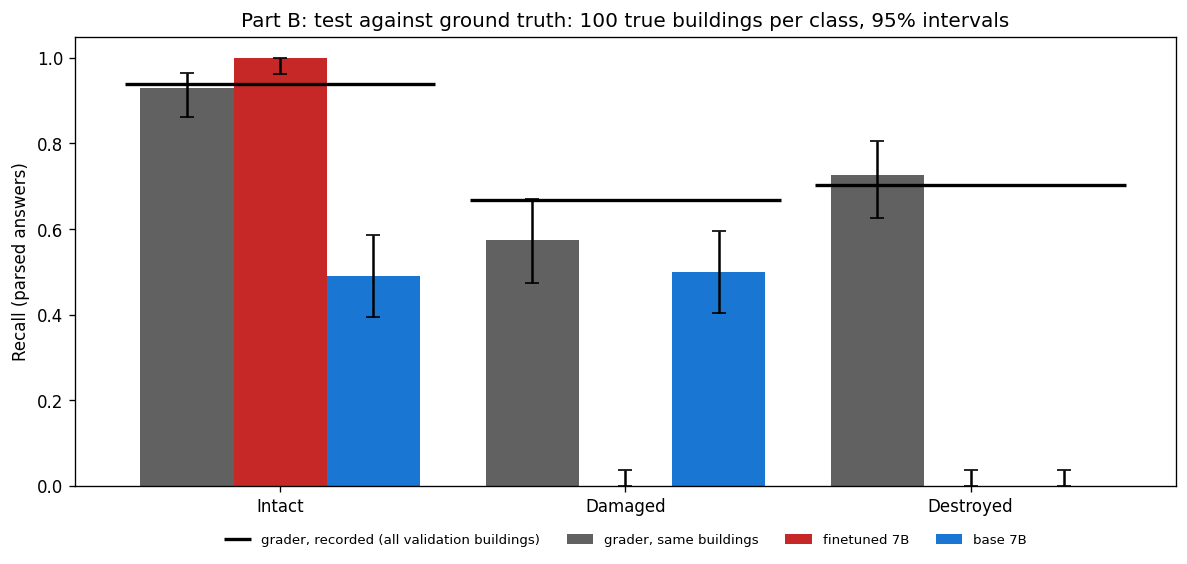

2689

In [9]:
# ── Cell 9: Confusion matrices, recall, the paired tests and the verdicts (rules fixed before the run) ──
from scipy.stats import binomtest

RUNS = ["grader"] + list(MODELS)        # the grader on the same buildings, then each 7B

def wilson(k, n, z=1.96):
    """95% Wilson interval of k successes in n."""
    if n == 0:
        return float("nan"), float("nan")
    p, z2 = k / n, z * z
    centre = (p + z2 / (2 * n)) / (1 + z2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z2 / (4 * n * n)) / (1 + z2 / n)
    return centre - half, centre + half

def interval_verdict(reference, lo, hi):
    if np.isnan(lo):
        return "no parsed answers"
    return "higher" if reference < lo else "lower" if reference > hi else "not distinguishable at this sample size"

def mcnemar(only_a, only_b):
    """Exact two-sided McNemar test on the buildings where exactly one of the two is right."""
    n = only_a + only_b
    return 1.0 if n == 0 else float(binomtest(only_a, n, 0.5).pvalue)

assert [round(v, 3) for v in wilson(14, 20)] == [0.481, 0.855] and [round(v, 3) for v in wilson(70, 100)] == [0.604, 0.781]
assert round(mcnemar(6, 0), 5) == 0.03125 and mcnemar(3, 3) == 1.0

# 1) Confusion matrices and recall per run (rows: true class; columns: the answer's class or "unparsed")
boot_rng = np.random.default_rng(SEED)
recall_rows, cm_rows = [], []
for run in RUNS:
    sub = answers[answers["run"] == run]
    cm = (pd.crosstab(sub["true_class"], sub["vlm_class"].fillna("unparsed"))
          .reindex(index=CLASSES, columns=CLASSES + ["unparsed"], fill_value=0))
    print(f"\n{run}: rows the true class, columns the answer ('unparsed' is the grader's 'None' for the grader)")
    print(cm.to_string())
    for cls in CLASSES:
        for col in CLASSES + ["unparsed"]:
            cm_rows.append({"run": run, "true_class": cls, "answer": col, "buildings": int(cm.at[cls, col])})
    outcomes = {}
    for cls in CLASSES:
        n = int(cm.loc[cls].sum())
        parsed = n - int(cm.at[cls, "unparsed"])
        right = int(cm.at[cls, cls])
        lo, hi = wilson(right, parsed)
        outcomes[cls] = (sub[(sub["true_class"] == cls) & sub["vlm_class"].notna()]["vlm_class"] == cls).to_numpy()
        both = sub[(sub["true_class"] == cls) & sub["vlm_class"].notna() & sub["grade_as_class"].notna()]
        recall_rows.append({
            "run": run, "class": cls, "buildings": n, "parsed": parsed, "right": right,
            "recall": round(right / parsed, 4) if parsed else None, "ci_low": round(lo, 4), "ci_high": round(hi, 4),
            "recall_unparsed_wrong": round(right / n, 4) if n else None,
            "grader_recorded_recall": round(GRADER_RECALL[cls], 4),
            "vs_recorded": interval_verdict(GRADER_RECALL[cls], lo, hi),
            "class_matches_own_grade": "" if run == "grader" else
                f"{int((both['vlm_class'] == both['grade_as_class']).sum())}/{len(both)}"})
    if all(len(o) for o in outcomes.values()):     # the mean of the three recalls, with a stratified bootstrap
        mean_recall = float(np.mean([o.mean() for o in outcomes.values()]))
        boots = np.mean([[boot_rng.choice(o, len(o)).mean() for o in outcomes.values()] for _ in range(BOOTSTRAP)], axis=1)
        lo, hi = np.percentile(boots, [2.5, 97.5])
    else:
        mean_recall, lo, hi = float("nan"), float("nan"), float("nan")
    recorded_mean = float(np.mean(list(GRADER_RECALL.values())))
    recall_rows.append({"run": run, "class": "mean of the three", "buildings": len(sub),
                        "parsed": int(sub["vlm_class"].notna().sum()),
                        "right": int((sub["vlm_class"] == sub["true_class"]).sum()),
                        "recall": round(mean_recall, 4), "ci_low": round(lo, 4), "ci_high": round(hi, 4),
                        "recall_unparsed_wrong": round(float(np.mean([(sub[sub["true_class"] == c]["vlm_class"] == c).mean()
                                                                      for c in CLASSES])), 4),
                        "grader_recorded_recall": round(recorded_mean, 4),
                        "vs_recorded": interval_verdict(recorded_mean, lo, hi), "class_matches_own_grade": ""})
recall = pd.DataFrame(recall_rows)
recall.to_csv(OUT_DIR / "part_b_recall.csv", index=False)
pd.DataFrame(cm_rows).to_csv(OUT_DIR / "part_b_confusion.csv", index=False)
print(f"\n{LABEL}: recall per run (parsed answers, 95% intervals), against the grader's recorded recall")
display(recall)

# 2) Paired on the same buildings: right only if the answer names the true class (unparsed and "None" are wrong)
right = (answers.assign(right=answers["vlm_class"] == answers["true_class"])
         .pivot(index="item", columns="run", values="right")
         .join(sample.set_index("item")["true_class"]))
paired = []
for a, b in [(m, "grader") for m in MODELS] + [tuple(MODELS)]:
    for cls in CLASSES + ["all three"]:
        w = right if cls == "all three" else right[right["true_class"] == cls]
        ra, rb = w[a].astype(bool), w[b].astype(bool)
        only_a, only_b = int((ra & ~rb).sum()), int((~ra & rb).sum())
        p = mcnemar(only_a, only_b)
        paired.append({"comparison": f"{a} vs {b}", "class": cls, "buildings": len(w), "both right": int((ra & rb).sum()),
                       f"only the first right": only_a, "only the second right": only_b,
                       "both wrong": int((~ra & ~rb).sum()), "mcnemar_p": round(p, 4),
                       "verdict": (f"{a} higher" if p < 0.05 and only_a > only_b else
                                   f"{a} lower" if p < 0.05 and only_a < only_b else
                                   "not distinguishable at this sample size")})
paired = pd.DataFrame(paired)
paired.to_csv(OUT_DIR / "part_b_paired.csv", index=False)
print("\nPaired on the same buildings (exact McNemar tests):")
display(paired)

print("\nThe main question, by the rule fixed before the run (paired, all sampled buildings):")
for _, row in paired[(paired["class"] == "all three") & paired["comparison"].str.endswith("vs grader")].iterrows():
    print(f"  {row['comparison']}: only the 7B right on {row['only the first right']}, only the grader on "
          f"{row['only the second right']}, p = {row['mcnemar_p']:.4f} -> {row['verdict']}")
print("Secondary, against the grader's recorded recall (mean of the three):")
for row in recall[(recall["class"] == "mean of the three") & recall["run"].isin(MODELS)].itertuples():
    print(f"  {row.run}: {row.recall:.4f} [{row.ci_low:.4f}, {row.ci_high:.4f}] against {row.grader_recorded_recall:.4f} "
          f"-> 7B {row.vs_recorded}")

# Chart: measured values only (this run; the grader's recorded recall from R16c step 5b)
x = np.arange(len(CLASSES))
fig, ax = plt.subplots(figsize=(10, 4.8), dpi=120)
for k, (run, color) in enumerate(zip(RUNS, ["#616161", "#c62828", "#1976d2"])):
    r = recall[(recall["run"] == run) & recall["class"].isin(CLASSES)].set_index("class").reindex(CLASSES)
    err = np.vstack([r["recall"] - r["ci_low"], r["ci_high"] - r["recall"]]).astype(float)
    ax.bar(x + (k - 1) * 0.27, r["recall"].astype(float), width=0.27, color=color, yerr=err, capsize=4,
           label="grader, same buildings" if run == "grader" else f"{run} 7B")
for i, cls in enumerate(CLASSES):
    ax.hlines(GRADER_RECALL[cls], i - 0.45, i + 0.45, colors="black", linewidth=2,
              label="grader, recorded (all validation buildings)" if i == 0 else None)
ax.set_xticks(x, CLASSES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Recall (parsed answers)")
ax.set_title(f"{LABEL}: {N_PER_CLASS} true buildings per class, 95% intervals")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4, frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "part_b_recall_chart.png", bbox_inches="tight")
plt.show()

config = {"label": LABEL, "smoke_test": SMOKE_TEST, "models": MODELS, "runs": runs, "n_per_class": N_PER_CLASS,
          "caps_used": caps_used, "seed": SEED, "min_area_px": MIN_AREA, "window_px": WINDOW, "zoom": ZOOM,
          "box_pad_px": BOX_PAD, "box_thickness_px": BOX_THICK, "context_px": CONTEXT, "precision": "fp16",
          "decoding": "greedy", "class_prompt": CLASS_PROMPT, "grade_prompt": GRADE_PROMPT,
          "grader": {"file": GRADER_PATH, "labels": GRADER_LABELS, "bias": GRADER_BIAS, "crop": GRADER_CROP,
                     "margin": GRADER_MARGIN, "regraded": regrade.tolist(), "recorded": expected.tolist(),
                     "grades_differing": off, "recorded_recall_on_graded": {c: round(v, 4) for c, v in GRADER_RECALL.items()}},
          "images": {"validation": len(val_pairs), "left_out_leaked": len(val_pairs) - len(clean_pairs),
                     "used": len(clean_pairs), "in_sample": int(sample["image"].nunique())},
          "true_buildings": buildings["true_class"].value_counts().reindex(CLASSES).astype(int).to_dict(),
          "versions": {"torch": torch.__version__, "transformers": transformers.__version__}}
(OUT_DIR / "part_b_config.json").write_text(json.dumps(config, indent=1), encoding="utf-8")

## 10. Output files

In [10]:
# ── Cell 10: The output files ──
for p in sorted(OUT_DIR.iterdir()):
    print(f"  {p.name:<28} {p.stat().st_size / 1024:.1f} KB")

  part_b_answers.csv           79.1 KB
  part_b_config.json           2.6 KB
  part_b_confusion.csv         1.0 KB
  part_b_examples.png          1568.9 KB
  part_b_grader_check.csv      0.2 KB
  part_b_paired.csv            0.9 KB
  part_b_recall.csv            1.1 KB
  part_b_recall_chart.png      36.3 KB
  part_b_sample.csv            33.2 KB
